# 5. Exercise: mixing in a quiet and in a sheared ocean

During PIRATA FR-36 (March 2026), turbulence was measured at 24 stations along 10°W. We compare two of them:

- **9.5°S (station 26)**: away from the equator, where currents are weak;
- **0°N (station 7)**: on the equator, where the Equatorial Undercurrent flows below the surface (part 3).

Is turbulence the same at both stations? Where does it come from? How much heat and oxygen does it move? We go step by step:

1. Compare the two profiles.
2. Check that we can trust $\varepsilon$.
3. Find where the turbulence comes from.
4. Compute the fluxes of heat and oxygen, and compare them with published values.
5. Check whether our two stations are representative of the whole section.

**How it works.** Most cells are ready: just run them. The cells marked **✏️ Your turn** are yours: replace the `...` with your code. The solution is hidden just below (click to show it). The answers to the questions are in the dropdowns: try first!

## Step 1. Two profiles

We start with the profiles of the VMP at our two stations. Open the file and look at what it contains.

In [18]:
# Load the libraries and open the file of VMP profiles
import numpy as np
import xarray as xr
import gsw
import matplotlib.pyplot as plt

prof = xr.open_dataset("data/fr36_profiles.nc")
prof

<xarray.Dataset> Size: 122kB
Dimensions:  (station: 24, pres: 125)
Coordinates:
  * pres     (pres) float64 1kB 1.0 3.0 5.0 7.0 9.0 ... 243.0 245.0 247.0 249.0
  * station  (station) <U6 576B 'stat4' 'stat5' 'stat6' ... 'stat26' 'stat27'
Data variables:
    temp     (station, pres) float64 24kB ...
    sal      (station, pres) float64 24kB ...
    o2       (station, pres) float64 24kB ...
    chla     (station, pres) float64 24kB ...
    eps      (station, pres) float64 24kB ...
    lat      (station) float64 192B ...
    lon      (station) float64 192B ...
    time     (station) datetime64[ns] 192B ...
    mld      (station) float64 192B ...
Attributes:
    title:           PIRATA FR-36, VMP-250 profiles along 10W, March 2026 (co...
    eps_processing:  ATOMIX levels, toolbox of C. Vic; 2-dbar medians of EPSI...

In [19]:
# For our two stations, compute the potential density and the stratification N2 from temperature and salinity
pres = prof.pres.values
stations = {"stat26": "tab:blue", "stat7": "tab:red"}     # 9.5°S, 0°N

col = {}
for s in stations:
    p = prof.sel(station=s)
    SA = gsw.SA_from_SP(p.sal.values, pres, float(p.lon), float(p.lat))
    CT = gsw.CT_from_t(SA, p.temp.values, pres)
    n2, p_mid = gsw.Nsquared(SA, CT, pres, lat=float(p.lat))
    col[s] = {"temp": p.temp.values, "sal": p.sal.values, "o2": p.o2.values,
              "sigma": gsw.sigma0(SA, CT), "N2": np.interp(pres, p_mid, n2),
              "mld": float(p.mld), "lat": float(p.lat)}

**✏️ Your turn (1 line).** The 20 °C isotherm (D20) is a common marker of the tropical thermocline (part 1). Compute D20 at each station: the first pressure where the temperature is below 20 °C.

In [20]:
# D20: the first pressure where the temperature is below 20 °C
for s in stations:
    col[s]["d20"] = ...

In [21]:
# D20: the first pressure where the temperature is below 20 °C
for s in stations:
    col[s]["d20"] = pres[np.argmax(col[s]["temp"] < 20)]

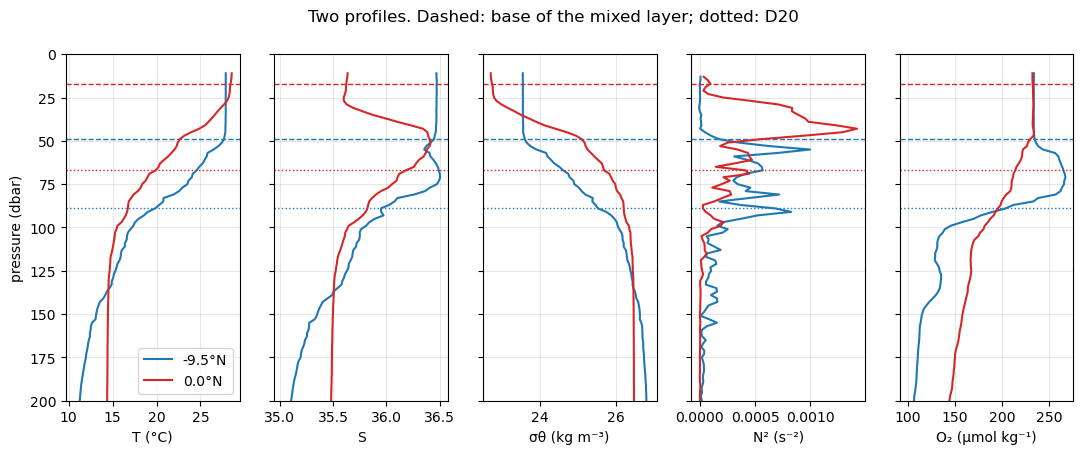

In [22]:
# Plot the profiles of the two stations side by side, with the base of the mixed layer and D20
fig, axs = plt.subplots(1, 5, figsize=(13, 4.5), sharey=True)
panels = [("temp", "T (°C)"), ("sal", "S"), ("sigma", "σθ (kg m⁻³)"), ("N2", "N² (s⁻²)"), ("o2", "O₂ (µmol kg⁻¹)")]
for s, c in stations.items():
    for ax, (key, label) in zip(axs, panels):
        ax.plot(col[s][key], pres, color=c, label=f"{col[s]['lat']:.1f}°N")
        ax.axhline(col[s]["mld"], color=c, ls="--", lw=1)
        ax.axhline(col[s]["d20"], color=c, ls=":", lw=1)
        ax.set_xlabel(label); ax.grid(alpha=0.3)
axs[0].set_ylim(200, 0); axs[0].set_ylabel("pressure (dbar)"); axs[0].legend()
fig.suptitle("Two profiles. Dashed: base of the mixed layer; dotted: D20");

::::{note} Questions
**1.1** Describe the vertical structure of the two profiles: the mixed layer, the thermocline and the water below. Where is the stratification strongest at each station? Compare $N^2$ at the two stations at the same depth.

**1.2** Describe the oxygen profiles. Where is the oxycline at each station, compared with the thermocline?

:::{dropdown} Answers
**1.1**
- Both surfaces are at about 28 °C. The mixed layer is about 50 m thick at 9.5°S, but only 17 m at the equator.
- The thermocline is shallower at the equator: D20 is at 67 dbar, against 89 dbar at 9.5°S.
- At the equator, the water is strongly stratified just below the mixed layer: $N^2$ is between $5 \times 10^{-4}$ and $1.4 \times 10^{-3}$ s⁻² from 25 to 48 dbar, with its maximum near 43 dbar. At the same depths, 9.5°S is still in its mixed layer and $N^2$ is close to zero: more than 10 times weaker.
- At 9.5°S, the stratification starts below 50 dbar, with peaks near 57 and 90 dbar.
- Below 100 dbar, $N^2$ is small at both stations.

**1.2**
- At 9.5°S, oxygen has a maximum below the mixed layer (about 265 µmol kg⁻¹ near 70 dbar), then drops sharply between 85 and 100 dbar: the oxycline lies at the base of the thermocline, close to D20.
- At the equator, oxygen decreases slowly from about 55 dbar downwards, without a sharp oxycline. Below 90 dbar, it stays 30 to 40 µmol kg⁻¹ higher than at 9.5°S.
:::
::::